# Notebook 3 — Modelo semântico, análise de resultados e `results.txt`
**Pessoa 3 (Mariana Almeida).** Parte das entregas dos notebooks 1 e 2, sem alterar os ficheiros delas: importa as funções de `src/parte1_base.py` e lê os resultados de `results/notebook2/`.

| Secção | O que faz | Saída em `results/notebook3/` |
|---|---|---|
| 1 | Dados e as 5 divisões da pessoa 1 | – |
| 2 | Previsões fora da divisão de B1 e S1 | – |
| 3 | Modelo semântico (embeddings + regressão logística) nas mesmas divisões | `semantic_<modelo>/predictions.csv` |
| 4 | Tabela das três partes com intervalos a 95% (bootstrap) | `tabela_modelos.csv` |
| 5 | F1 por especialidade + matriz de confusão | `f1_por_classe.csv`, `confusao_<modelo>.png` |
| 6 | Onde falham: textos repetidos, Surgery, pares confundidos | `pares_confundidos.csv` |
| 7 | Exemplos de erros e acertos para a Discussão | `exemplos_candidatos.csv` |
| 8 | `results.txt` com o modelo final da pessoa 2 | `results.txt` (raiz) |

**Kernel:** `Projeto2 LN (.venv)`.

## 1. Dados e divisões

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(root / 'src'))

#Person 1's code (via person 2's module), imported without changes: same data preparation, keyword handling, class weights and metrics
from parte1_base import prepare_data, prepare_texts, class_weights, measure, specialties, load_test

data_folder = root / 'data'
part2_folder = root / 'results' / 'notebook2'
study_folder = root / 'results' / 'notebook3'
study_folder.mkdir(parents=True, exist_ok=True)

data = prepare_data(pd.read_csv(data_folder / 'train.csv', sep=';', keep_default_na=False))
print(len(data), 'cases,', data['group_id'].nunique(), 'groups')

2613 cases, 1817 groups


In [2]:
#The 5 grouped folds of person 1 (StratifiedGroupKFold, seed 42), read from person 2's out-of-fold predictions
#so every model in this notebook is evaluated on exactly the same validation cases
reference = pd.read_csv(part2_folder / 'class_weights_q1' / 'predictions.csv').set_index('row_id').sort_index()
assert (reference.index == data['row_id']).all()
assert (reference['medical_specialty'].values == data['medical_specialty'].values).all(), 'labels do not match the folds file'
data['fold'] = reference['fold'].values
print(data['fold'].value_counts().sort_index().to_dict())

{0: 524, 1: 529, 2: 516, 3: 518, 4: 526}


## 2. Modelos anteriores: B1 (pessoa 1) e S1 (pessoa 2)
- **B1:** melhor configuração da pessoa 1, corrida de novo pela pessoa 2 (`start_person1_best`).
- **S1:** configuração final da pessoa 2 (`class_weights_q1`, igual a `s1_final_config.json`), **ainda sem augmentation**.

In [3]:
def load_predictions(folder):
    table = pd.read_csv(folder / 'predictions.csv').set_index('row_id').sort_index()
    return table['prediction'].reindex(data['row_id']).values

predictions = {
    'B1': load_predictions(part2_folder / 'start_person1_best'),
    'S1': load_predictions(part2_folder / 'class_weights_q1'),
}
gold = data['medical_specialty'].values
for name, pred in predictions.items():
    m = measure(gold, pred)
    print(f"{name}: acc={m['accuracy']:.3f}  macroF1={m['macro_f1']:.3f}  minF1={m['min_f1']:.3f}")

B1: acc=0.593  macroF1=0.631  minF1=0.447
S1: acc=0.596  macroF1=0.636  minF1=0.463


## 3. Modelo semântico pré-treinado
Cada caso é transformado num vetor por um modelo de frases pré-treinado e congelado. Por cima, uma regressão logística é treinada em cada divisão com os mesmos pesos de classe do S1 (q=1).

- A preparação é a mesma da pessoa 1: a 1.ª keyword é retirada quando é o nome da especialidade.
- O texto de entrada é `description + sample_name + keywords + transcription`. O modelo corta o que passar de `max_seq_length` tokens, ou seja, só lê o início da nota (ver `TRUNCATION` para outras opções).
- Os embeddings ficam guardados em cache (`.npy`), por isso só se calculam uma vez por modelo.

Modelos a experimentar em `MODEL_NAME`:
- `sentence-transformers/all-MiniLM-L6-v2`: geral, rápido;
- `pritamdeka/S-PubMedBert-MS-MARCO`: biomédico;
- `emilyalsentzer/Bio_ClinicalBERT`: clínico, sem treino para frases (média dos tokens).

In [4]:
from sentence_transformers import SentenceTransformer
import torch

MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
TRUNCATION = 'head'   # 'head' = start of the text; 'head_tail' = first and last half of the token budget
C = 1.0               # inverse regularisation strength of the logistic regression
device = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
slug = MODEL_NAME.split('/')[-1]

texts = prepare_texts(data, keywords='strip')
inputs = (texts['description'] + ' | ' + texts['sample_name'] + ' | ' + texts['keywords'] + ' | ' + texts['transcription']).tolist()

encoder = SentenceTransformer(MODEL_NAME, device=device)

def head_tail(text, budget):
    tokens = encoder.tokenizer.tokenize(text)
    if len(tokens) <= budget:
        return text
    half = budget // 2
    return encoder.tokenizer.convert_tokens_to_string(tokens[:half] + tokens[-half:])

def embed(texts_to_encode, cache):
    if cache.exists():
        return np.load(cache)
    if TRUNCATION == 'head_tail':
        texts_to_encode = [head_tail(t, encoder.max_seq_length - 2) for t in texts_to_encode]
    vectors = encoder.encode(texts_to_encode, batch_size=32, show_progress_bar=False, normalize_embeddings=True)
    np.save(cache, vectors)
    return vectors

X = embed(inputs, study_folder / f'emb_{slug}_{TRUNCATION}.npy')
print(X.shape, 'max_seq_length =', encoder.max_seq_length, 'device =', device)

/Users/marianaalmeida/Desktop/MEIC/LN/Trabalhos/Projeto2-NLP-task/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7618.88it/s]

(2613, 384) max_seq_length = 256 device = mps


In [5]:
#Out-of-fold predictions on person 1's folds
semantic_pred = np.empty(len(data), dtype=object)
for fold in sorted(data['fold'].unique()):
    train, valid = data['fold'] != fold, data['fold'] == fold
    classifier = LogisticRegression(C=C, max_iter=3000)
    classifier.fit(X[train], gold[train], sample_weight=class_weights(list(gold[train]), q=1))
    semantic_pred[valid.values] = classifier.predict(X[valid])

name = f'Sem_{slug}'
predictions[name] = semantic_pred
out = study_folder / f'semantic_{slug}_{TRUNCATION}'
out.mkdir(exist_ok=True)
pd.DataFrame({'row_id': data['row_id'], 'group_id': data['group_id'], 'medical_specialty': gold,
              'prediction': semantic_pred, 'fold': data['fold']}).to_csv(out / 'predictions.csv', index=False)
m = measure(gold, semantic_pred)
print(f"{name}: acc={m['accuracy']:.3f}  macroF1={m['macro_f1']:.3f}  minF1={m['min_f1']:.3f}")

Sem_all-MiniLM-L6-v2: acc=0.540  macroF1=0.573  minF1=0.387


## 4. Tabela das três partes com intervalos
Intervalo de confiança a 95% por bootstrap: os 2613 casos fora da divisão são reamostrados com reposição 1000 vezes. Quando os intervalos de dois modelos se sobrepõem muito, a diferença entre eles não é clara.

In [6]:
def bootstrap_interval(gold, pred, n=1000, seed=42):
    rng = np.random.default_rng(seed)
    scores = {'accuracy': [], 'macro_f1': [], 'min_f1': []}
    for _ in range(n):
        idx = rng.integers(0, len(gold), len(gold))
        m = measure(gold[idx], pred[idx])
        for key in scores:
            scores[key].append(m[key])
    return {key: np.percentile(values, [2.5, 97.5]) for key, values in scores.items()}

rows = []
for name, pred in predictions.items():
    m, ci = measure(gold, pred), bootstrap_interval(gold, pred)
    rows.append({'model': name, **{f'{k}': round(m[k], 3) for k in ['accuracy', 'macro_f1', 'min_f1']},
                 **{f'{k}_95ci': f'[{ci[k][0]:.3f}, {ci[k][1]:.3f}]' for k in ci}, 'meets_thresholds': m['meets_thresholds']})
summary = pd.DataFrame(rows).set_index('model')
summary.to_csv(study_folder / 'tabela_modelos.csv')
summary

,accuracy,macro_f1,min_f1,accuracy_95ci,macro_f1_95ci,min_f1_95ci,meets_thresholds
model,,,,,,,
B1,0.593,0.631,0.447,"[0.575, 0.611]","[0.607, 0.652]","[0.359, 0.487]",True
S1,0.596,0.636,0.463,"[0.578, 0.615]","[0.611, 0.657]","[0.371, 0.503]",True
Sem_all-MiniLM-L6-v2,0.540,0.573,0.387,"[0.520, 0.560]","[0.551, 0.596]","[0.329, 0.415]",True


## 5. F1 por especialidade e matriz de confusão

In [7]:
per_class = pd.DataFrame({name: pd.DataFrame(measure(gold, pred)['per_class']).set_index('specialty')['f1'] for name, pred in predictions.items()})
per_class['support'] = pd.Series(gold).value_counts().reindex(per_class.index)
per_class = per_class.sort_values('support', ascending=False).round(3)
per_class.to_csv(study_folder / 'f1_por_classe.csv')
per_class.style.highlight_max(axis=1, subset=list(predictions), color='#cfe8cf')

,B1,S1,Sem_all-MiniLM-L6-v2,support
specialty,,,,
Surgery,0.469000,0.486000,0.387000,876
Cardiovascular-Pulmonary,0.648000,0.648000,0.613000,299
Orthopedic,0.595000,0.583000,0.576000,292
Radiology,0.522000,0.534000,0.409000,217
General Medicine,0.801000,0.798000,0.617000,207
Gastroenterology,0.644000,0.647000,0.622000,192
Neurology,0.586000,0.589000,0.590000,181
Obstetrics-Gynecology,0.643000,0.633000,0.634000,135
Neurosurgery,0.447000,0.463000,0.448000,78


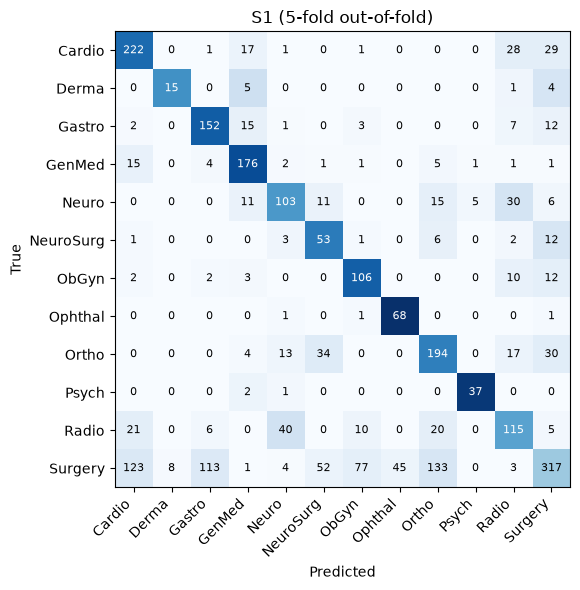

In [8]:
#Confusion matrix with short readable labels (required in the paper); rows = true, columns = predicted
short = {'Cardiovascular-Pulmonary': 'Cardio', 'Dermatology': 'Derma', 'Gastroenterology': 'Gastro', 'General Medicine': 'GenMed',
         'Neurology': 'Neuro', 'Neurosurgery': 'NeuroSurg', 'Obstetrics-Gynecology': 'ObGyn', 'Ophthalmology': 'Ophthal',
         'Orthopedic': 'Ortho', 'Psychiatry-Psychology': 'Psych', 'Radiology': 'Radio', 'Surgery': 'Surgery'}

def plot_confusion(name):
    matrix = confusion_matrix(gold, predictions[name], labels=specialties)
    fig, ax = plt.subplots(figsize=(7, 6))
    shares = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(shares, cmap='Blues')
    for i in range(len(specialties)):
        for j in range(len(specialties)):
            ax.text(j, i, matrix[i, j], ha='center', va='center', fontsize=8, color='white' if shares[i, j] > 0.5 else 'black')
    labels = [short[s] for s in specialties]
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{name} (5-fold out-of-fold)')
    fig.tight_layout()
    fig.savefig(study_folder / f'confusao_{name}.png', dpi=200)
    plt.show()

plot_confusion('S1')

## 6. Onde é que os modelos falham
- **Textos repetidos:** casos cujo grupo (mesma descrição ou transcrição) tem mais do que uma etiqueta no treino. Aí nenhum modelo pode acertar em todos.
- **Pares mais confundidos:** em princípio Surgery contra as especialidades cirúrgicas e Radiology contra Neurology/Cardio.

In [9]:
labels_per_group = data.groupby('group_id')['medical_specialty'].nunique()
data['conflicting_group'] = data['group_id'].map(labels_per_group) > 1
print(f"{data['conflicting_group'].mean():.1%} of the cases are in a group with more than one label")

by_type = pd.DataFrame({name: pd.Series(pred == gold).groupby(data['conflicting_group'].values).mean() for name, pred in predictions.items()})
by_type.index = by_type.index.map({False: 'consistent group', True: 'conflicting labels'})
by_type.round(3)

57.0% of the cases are in a group with more than one label


,B1,S1,Sem_all-MiniLM-L6-v2
consistent group,0.770,0.774,0.659
conflicting labels,0.459,0.462,0.450


In [10]:
pairs = (pd.DataFrame({'true': gold, 'predicted': predictions['S1']})
         .query('true != predicted').value_counts().rename('errors').reset_index())
pairs['share_of_S1_errors'] = (pairs['errors'] / pairs['errors'].sum()).round(3)
pairs.to_csv(study_folder / 'pares_confundidos.csv', index=False)
pairs.head(10)

,true,predicted,errors,share_of_S1_errors
0,Surgery,Orthopedic,133,0.126
1,Surgery,Cardiovascular-Pulmonary,123,0.117
2,Surgery,Gastroenterology,113,0.107
3,Surgery,Obstetrics-Gynecology,77,0.073
4,Surgery,Neurosurgery,52,0.049
5,Surgery,Ophthalmology,45,0.043
6,Radiology,Neurology,40,0.038
7,Orthopedic,Neurosurgery,34,0.032
8,Neurology,Radiology,30,0.028
9,Orthopedic,Surgery,30,0.028


## 7. Exemplos para a Discussão
São precisos pelo menos 3 erros concretos, cada um com excerto, etiqueta prevista, etiqueta correta e interpretação. Os candidatos ficam em `exemplos_candidatos.csv` e escolhem-se à mão. Bons tipos:
- todos os modelos erram;
- o modelo semântico acerta e o S1 erra, ou o contrário;
- etiquetas que parecem erradas, que o professor pede para discutir.

In [11]:
candidates = data[['row_id', 'medical_specialty', 'conflicting_group', 'description', 'sample_name', 'keywords']].copy()
for name, pred in predictions.items():
    candidates[name] = pred
names = list(predictions)
candidates['n_wrong'] = sum((candidates[n] != candidates['medical_specialty']).astype(int) for n in names)
candidates['type'] = np.select(
    [candidates['n_wrong'] == len(names), (candidates['S1'] != candidates['medical_specialty']) & (candidates['n_wrong'] < len(names)),
     candidates['n_wrong'] == 0],
    ['all wrong', 'S1 wrong, other right', 'all right'], 'other')
candidates.to_csv(study_folder / 'exemplos_candidatos.csv', index=False)
candidates['type'].value_counts()

type
all right                1175
all wrong                 821
other                     383
S1 wrong, other right     234
Name: count, dtype: int64

In [12]:
def show(row_id, chars=500):
    row = data.loc[data['row_id'] == row_id].iloc[0]
    print(f"row_id {row_id} | gold: {row['medical_specialty']} | " + ' | '.join(f'{n}: {predictions[n][row_id]}' for n in predictions))
    print('description:', row['description'].strip()); print('sample_name:', row['sample_name'].strip()); print('keywords:', row['keywords'][:200])
    print('transcription:', row['transcription'][:chars].replace(',', ', '), '...\n')

for row_id in candidates.query("type == 'all wrong' and not conflicting_group").sample(3, random_state=0)['row_id']:
    show(row_id)

row_id 2280 | gold: Surgery | B1: Gastroenterology | S1: Gastroenterology | Sem_all-MiniLM-L6-v2: Gastroenterology
description: Laparoscopic appendectomy.  Acute suppurative appendicitis.  A CAT scan of the abdomen and pelvis was obtained revealing findings consistent with acute appendicitis.  There was no evidence of colitis on the CAT scan.
sample_name: Appendectomy Laparoscopic - 1
keywords: surgery, abdomen, pelvis, laparoscopic appendectomy, suppurative appendicitis, veress needle, acute appendicitis, appendix, appendectomy, pneumoperitoneum, laparoscopic, appendicitis
transcription: PREOPERATIVE DIAGNOSIS: Acute appendicitis., POSTOPERATIVE DIAGNOSIS:  Acute suppurative appendicitis., PROCEDURE PERFORMED: Laparoscopic appendectomy., ANESTHESIA: General endotracheal and Marcaine 0.25% local., INDICATIONS:  This 29-year-old female presents to ABCD General Hospital Emergency Department on 08/30/2003 with history of acute abdominal pain.  On evaluation,  it was noted that the patient

## 8. `results.txt`
Usa o modelo final da pessoa 2 (`results/notebook2/s1_final_model.joblib`, treinado com os 2613 casos) no **teste limpo** (398 casos). O teste só serve para isto.

⚠️ **Por agora é provisório**: o passo 8 (augmentation) da pessoa 2 ainda não foi corrido. Se mudar a escolha do modelo, é preciso correr esta secção outra vez.

In [13]:
import joblib

def write_results(predictions_test, n_test, path=root / 'results.txt'):
    lines = [str(p).strip() for p in predictions_test]
    assert len(lines) == n_test, f'{len(lines)} predictions for {n_test} test cases'
    invalid = sorted(set(lines) - set(specialties))
    assert not invalid, f'invalid labels: {invalid}'
    Path(path).write_text('\n'.join(lines) + '\n', encoding='utf-8')
    assert Path(path).read_text(encoding='utf-8').splitlines() == lines
    print(f'{path}: {len(lines)} lines, {len(set(lines))} specialties')

test = load_test(data_folder / 'test_no_labels.csv')
final_model = joblib.load(part2_folder / 's1_final_model.joblib')
write_results(final_model.predict(test), len(test))
pd.Series(Path(root / 'results.txt').read_text().splitlines()).value_counts()

/Users/marianaalmeida/Desktop/MEIC/LN/Trabalhos/Projeto2-NLP-task/results.txt: 398 lines, 12 specialties


Surgery                     116
Orthopedic                   43
Cardiovascular-Pulmonary     43
General Medicine             35
Gastroenterology             35
Radiology                    28
Neurology                    28
Neurosurgery                 21
Obstetrics-Gynecology        21
Ophthalmology                15
Psychiatry-Psychology        11
Dermatology                   2
Name: count, dtype: int64

## 9. Notas para o Gonçalo (relatório)
- Tabelas e figuras a usar:
- Exemplos escolhidos:
- Limitações: